# Week 6 In-Class Activity

This week, we will start to examine time scales of variability in time series data. To help us to start thinking about this, we will take a look at the downtown Toronto daily temperature time series.

Let's load the data.

In [1]:
# import packages
import numpy as np
from matplotlib import pyplot as plt
import scipy.stats as st
import matplotlib as mpl
mpl.rc('font',size=16) #set default font size and weight for plots

In [2]:
# load downtown Toronto Station data (in deg C)
filename = "tor19012020.csv"
T = np.genfromtxt(filename, dtype='float',delimiter = ',')[1:,3] # Just extract daily mean temperature

In [3]:
T = T[~np.isnan(T)]

In [4]:
T.shape

(43762,)

Go ahead and plot the time series and add the best-fit line. The data start from Jan. 1st 1901 to Dec. 31st 2020.

Text(0.5, 1.0, 'Daily Downtown Toronto Temperature Time Series (1901-2020)')

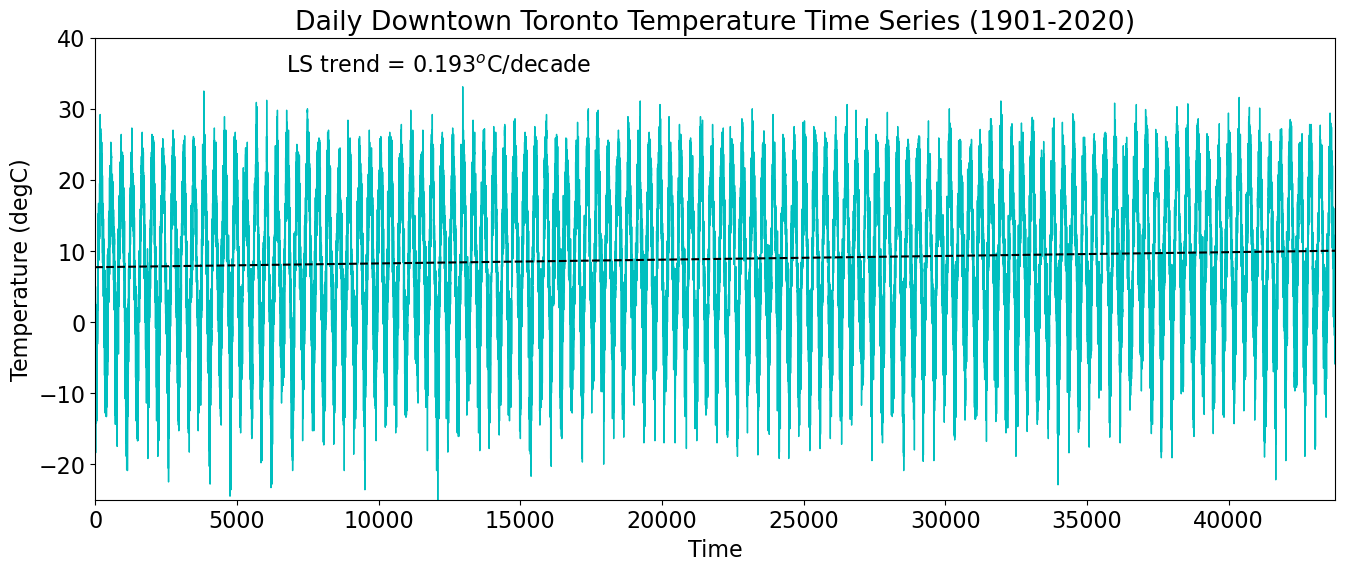

In [5]:
# plot the time series
# Create time index for plotting and for regression
time = np.arange(0,len(T))

#  Plot the data
plt.figure(figsize=(16,6))

# plot time series
plt.plot(time,T,'c',linewidth=1)

# calculate best-fit line
slope, intercept, r_value, p_value, s_a1 = st.linregress(time,T)
T_hat = intercept + slope*time

# plot best-fit line
plt.plot(time,T_hat,'k',linestyle='--')

# ticks, labels, etc.
#plt.xticks(np.arange(0,len(time),5*365),["1981","1986","1991","1996","2001","2006","2011"])
plt.xlim(0,len(time)) 
plt.text(0.4, 0.925,'LS trend = ' + str(np.round(slope*10*365,3)) + '$^o$C/decade', ha='right', 
         transform=plt.gca().transAxes, color = 'k') #we multiply by 40 because our unit of time is seasons but we
                                                        #want to report the trend in deg C per decade
plt.ylim(-25,40)
plt.ylabel("Temperature (degC)")
plt.xlabel("Time")
plt.title("Daily Downtown Toronto Temperature Time Series (1901-2020)")

# I. Effective Sample Size

Above you computed the standard error of the slope. Use this to compute the 95% confidence intervals on the slope. What is $N$?

In [6]:
#find t_crit for our 95% confidence intervals on our slope
t_crit = st.t.ppf(0.975,len(T)-2)
print(t_crit)
confidence_interval = t_crit*s_a1
print("The true value of the 1901-2020 slope is then", np.round(slope,3), "+/-", np.round(confidence_interval,3), "K/decade")

1.960018196965354
The true value of the 1901-2020 slope is then 0.0 +/- 0.0 K/decade


This looks really small! 

How would you report the trend in units of deg C per decade?

In [7]:
print("The true value of the 1901-2020 slope is then", np.round(slope*10*365,3), "+/-", np.round(confidence_interval*10*365,3), "K/decade")

The true value of the 1901-2020 slope is then 0.193 +/- 0.028 K/decade


**Reflection Question:**

What time scales of variability do you see in this time series? Based on what we have learned so far, what can you determine about the autocorrelation of this time series just by looking at it?

Let's take a look at the autocorrelation function to see whether we are correct.

We first calculate the autocorrelation function.

In [11]:
# np.correlate actually gives the covariance. We need to find the covariance of the deviations from the mean and then
#  divide the the tau=0 covariance, i.e., the variance to get the correlation

Ts = (T-np.mean(T))/np.std(T)

Tcorr = np.correlate(Ts,Ts,'same')/len(T)

In [12]:
print(T.shape[0],Tcorr.shape)

43762 (43762,)


And then plot it as a function of lag. Just show the positive lags.

Text(0.5, 0, 'Lag')

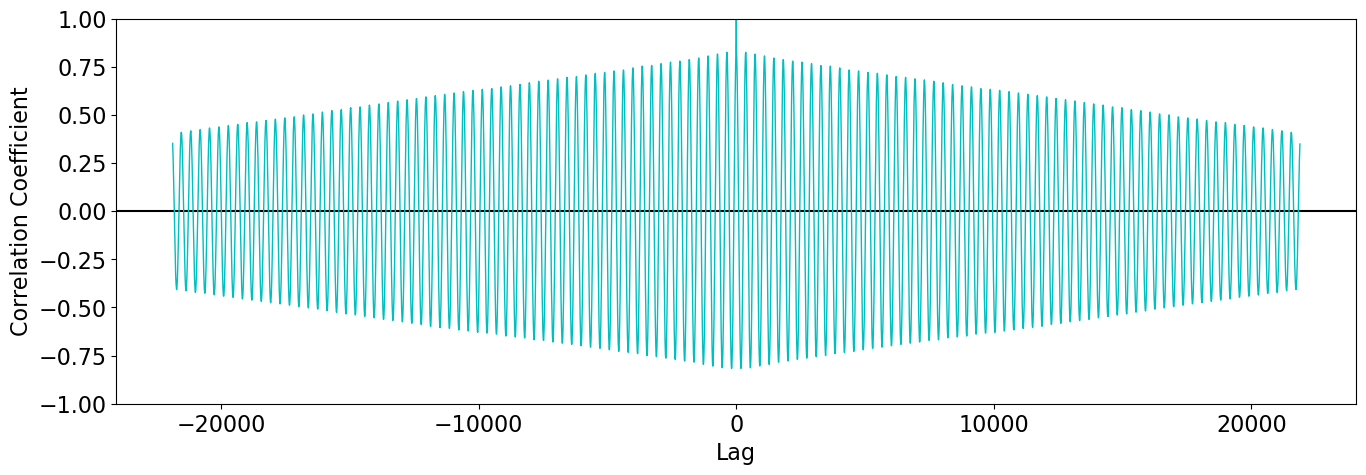

In [13]:
#plot the autocorrelation function
fig = plt.figure(figsize=(16,5))

# x-value for plotting
x = np.arange(0,len(Tcorr),1)
series = [i-int(len(Tcorr)/2.0) for i in x]

#plot series
plt.axhline(0,color='k')
plt.plot(series,Tcorr,'c',linewidth=1)
#plt.xlim(0,int(len(T)/2))
plt.ylim(-1,1)
#plt.xlim(0,400)
plt.ylabel('Correlation Coefficient')
plt.xlabel('Lag')

What is going on at lag=0? Is it equal to 1? It's hard to tell. Let's just double check - it's always good to double, triple, quadruple check that you are getting what you expect to get. You may need to adjust your `plt.xlim()` limits to zoom in on lag=0.

What is the lag-1 autocorrelation of this time series? How would you adjust $N$ to take the high autocorrelation into account?

In [14]:
# compute the effective sample size using the lag-1 autocorrelation
Tcorr_lag1 = Tcorr[int(len(T)/2)+1]
print(np.round(Tcorr_lag1,2))

0.95


In [15]:
Neff = len(T) * (1 - Tcorr_lag1)/(1 + Tcorr_lag1)
print(int(Neff),len(T))

1234 43762


Now, recalculate the confidence intervals on the slope using the effective sample size. How do they differ?

In [16]:
#find t_crit for our 95% confidence intervals on our slope
t_crit = st.t.ppf(0.975,int(Neff)-2)
resids = T - T_hat
std_err_ne = np.sqrt(np.sum(resids**2)/((Neff-2)*np.sum((time -np.mean(time))**2)))
print(t_crit)
confidence_interval = t_crit*std_err_ne
print("The true value of the 1901-2020 slope is then", np.round(slope*10*365,3), "+/-", np.round(confidence_interval*10*365,3), "K/decade")

1.96189139030643
The true value of the 1901-2020 slope is then 0.193 +/- 0.167 K/decade




Ok, now let's see what happens to the autocorrelation function if we *detrend* our time series. 

First, plot the detrended time series.

Text(0.5, 1.0, 'Detrended Daily Downtown Toronto Temperature Time Series (1981-2008)')

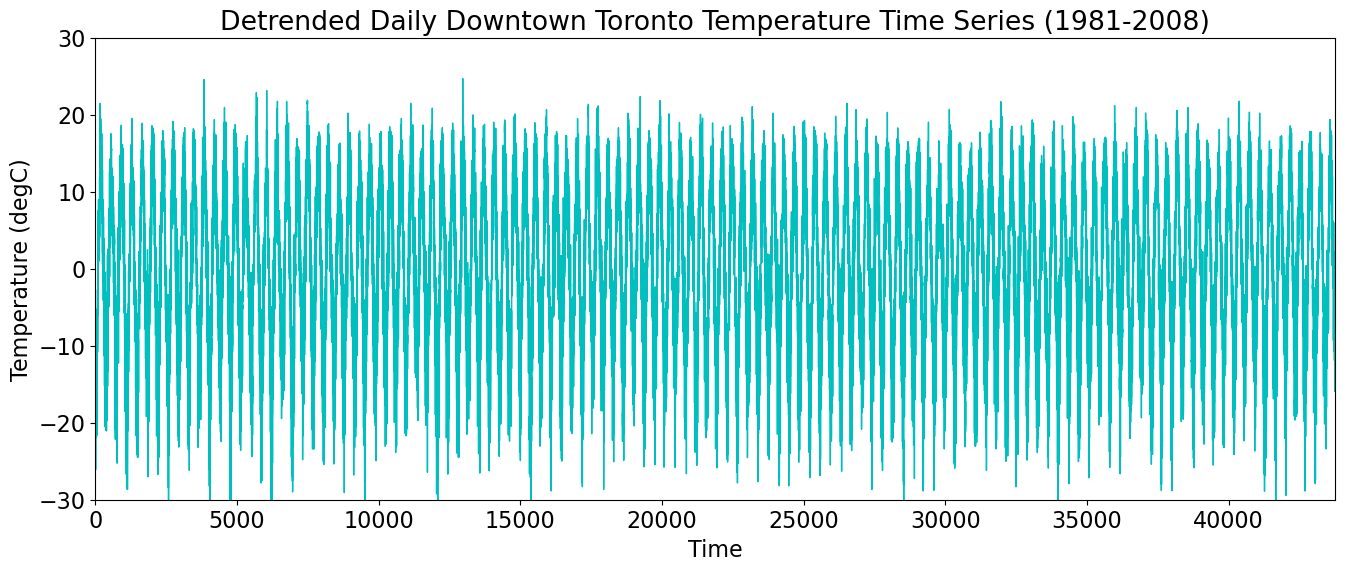

In [17]:
# plot the detrended time series
plt.figure(figsize=(16,6))

# plot time series
T_dtr = T - T_hat
plt.plot(time,T_dtr,'c',linewidth=1)

# ticks, labels, etc.
#plt.xticks(np.arange(0,len(time),5*365),["1981","1986","1991","1996","2001","2006","2011"])
plt.xlim(0,len(time))
plt.ylim(-30,30)
plt.ylabel("Temperature (degC)")
plt.xlabel("Time")
plt.title("Detrended Daily Downtown Toronto Temperature Time Series (1981-2008)")

**Reflection Question:**

What time scales of variability remain after detrending? How do you think the autocorrelation function has or hasn't changed?

Let's plot the autocorrelation function of the detrended time series.

In [18]:
# np.correlate actually gives the covariance. We need to find the covariance of the deviations from the mean and then
#  divide the the tau=0 covariance, i.e., the variance to get the correlation

Tcorr_dtr = np.correlate((T_dtr-np.mean(T_dtr))/np.std(T_dtr),(T_dtr-np.mean(T_dtr))/np.std(T_dtr),'same')/len(T_dtr)

Plot both the original ACF and the one for the detrended time series.

Text(0.5, 0, 'Lag')

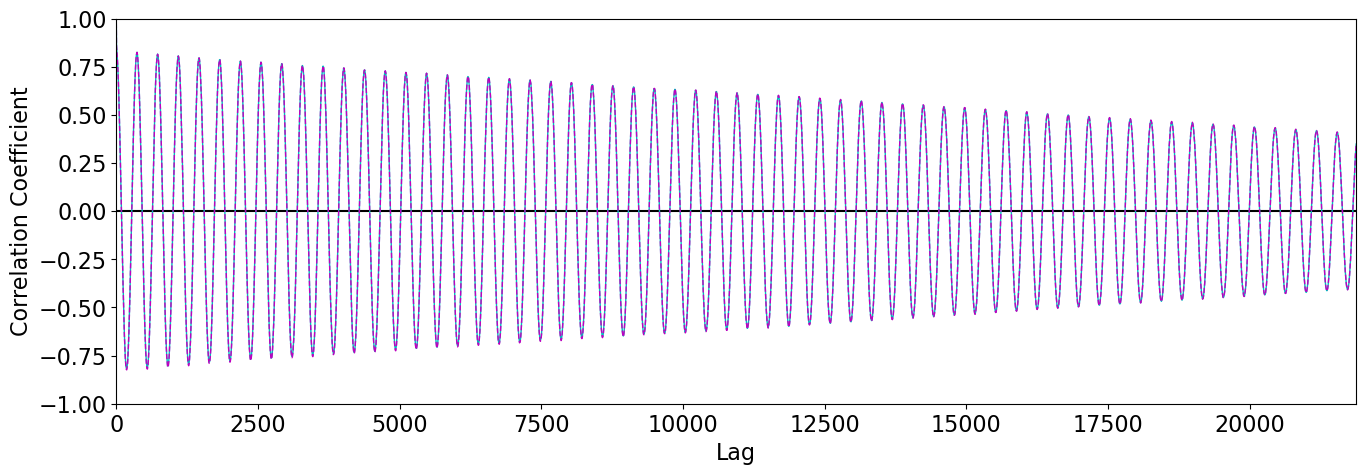

In [19]:
#plot the autocorrelation function
fig = plt.figure(figsize=(16,5))

# x-value for plotting
x = np.arange(0,len(T),1)
series = [i-int(len(T)/2.0) for i in x]

#plot series
plt.axhline(0,color='k')
plt.plot(series,Tcorr,'c',linewidth=1)
plt.plot(series,Tcorr_dtr,'m--',linewidth=1)
plt.xlim(0,int(len(T)/2))
#plt.xlim(0,400)
plt.ylim(-1,1)
plt.ylabel('Correlation Coefficient')
plt.xlabel('Lag')

Do you see a difference in the autocorrelation function? Why or why not? What does this tell you about the dominant time scales of variability in this data set?

**Reflection Question:**

If we wanted to isolate the variability associated with the long-term trend, how might we go about this? Can we remove the seasonal cycle? Removing the seasonal cycle is a common approach in climate data analysis. There are several ways to do this. Here we will try a simple technique.

## II. Removing the Seasonal Cycle

Let's create a characteristic (aka a *climatological*) seasonal cycle that we will substract

In [31]:
T_short = T[0:43435]

In [33]:
T_reshape = T_short.reshape(119,365)

In [36]:
T_clim = T_reshape.mean(axis=0)

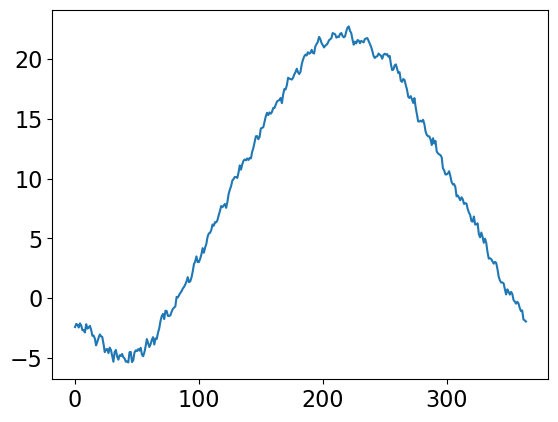

In [53]:
plt.plot(T_clim)

In [37]:
T_noseasons = T_reshape - T_clim

In [38]:
T_noseasons = T_noseasons.ravel()

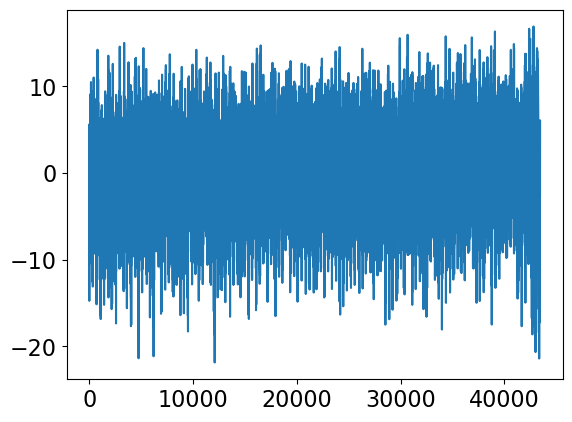

In [39]:
plt.plot(T_noseasons)

In [40]:
Tcorr_noseasons = np.correlate((T_noseasons-np.mean(T_noseasons))/np.std(T_noseasons),(T_noseasons-np.mean(T_noseasons))/np.std(T_noseasons),'same')/len(T_noseasons)

Text(0.5, 0, 'Lag')

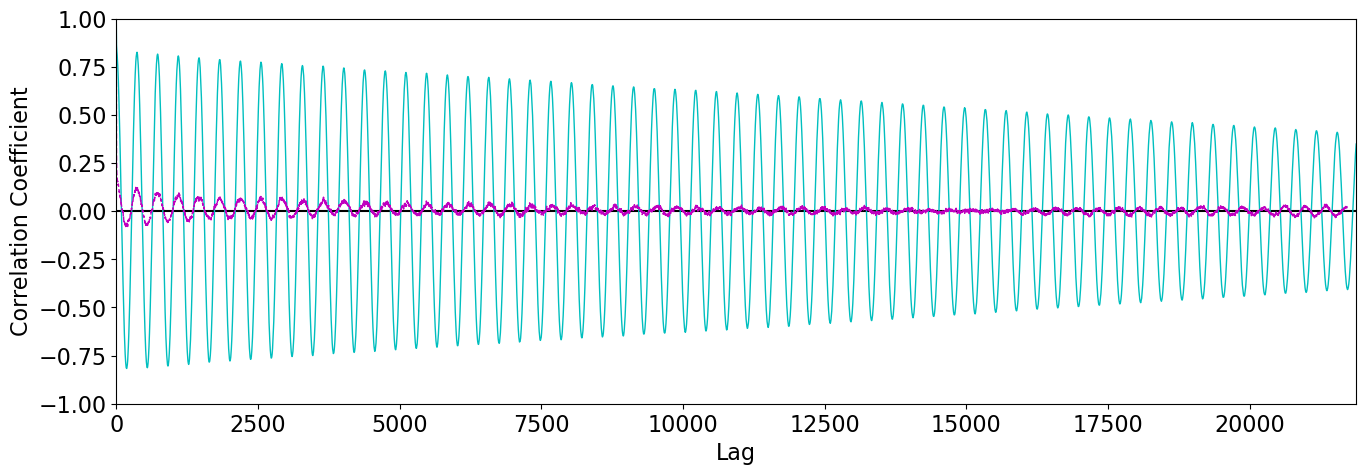

In [52]:
#plot the autocorrelation function
fig = plt.figure(figsize=(16,5))

# x-value for plotting
x = np.arange(0,len(T),1)
series = [i-int(len(T)/2.0) for i in x]

x2 = np.arange(0,len(T_noseasons),1)
series2 = [i-int(len(T_noseasons)/2.0) for i in x2]

#plot series
plt.axhline(0,color='k')
plt.plot(series,Tcorr,'c',linewidth=1)
plt.plot(series2,Tcorr_noseasons,'m--',linewidth=1)
plt.xlim(0,int(len(T)/2))
#plt.xlim(0,400)
plt.ylim(-1,1)
plt.ylabel('Correlation Coefficient')
plt.xlabel('Lag')